In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split
from src.common import load_train, RATING_COLS, RACINE, SEED

df = load_train()
df["satisfait"] = 1 - df["insatisfait"]

(RACINE / "figures").mkdir(exist_ok=True)
(RACINE / "results").mkdir(exist_ok=True)


In [2]:
tableau = pd.DataFrame({note: df.groupby(note)["satisfait"].mean() * 100 for note in RATING_COLS}).T
tableau.columns = [1, 2, 3, 4, 5]
tableau["ecart"] = tableau[5] - tableau[1]
tableau = tableau.sort_values("ecart", ascending=False).round(1)

tableau.to_csv(RACINE / "results" / "02_satisfaction_par_note.csv")
tableau


,1,2,3,4,5,ecart
Online boarding,13.8,11.5,13.6,62.3,87.2,73.4
Inflight wifi service,32.5,24.9,25.1,59.9,99.1,66.5
Inflight entertainment,14.0,21.3,27.0,61.2,64.8,50.9
On-board service,19.4,25.6,31.6,53.7,64.2,44.9
Seat comfort,22.3,22.4,21.2,56.1,65.0,42.7
Cleanliness,19.6,21.3,43.2,53.5,60.9,41.3
Leg room service,20.3,27.5,27.2,58.2,61.4,41.2
Checkin service,23.9,25.2,44.8,46.0,61.0,37.1
Ease of Online booking,37.6,30.4,30.8,53.1,73.8,36.2
Food and drink,20.0,38.8,39.6,52.5,54.9,34.9


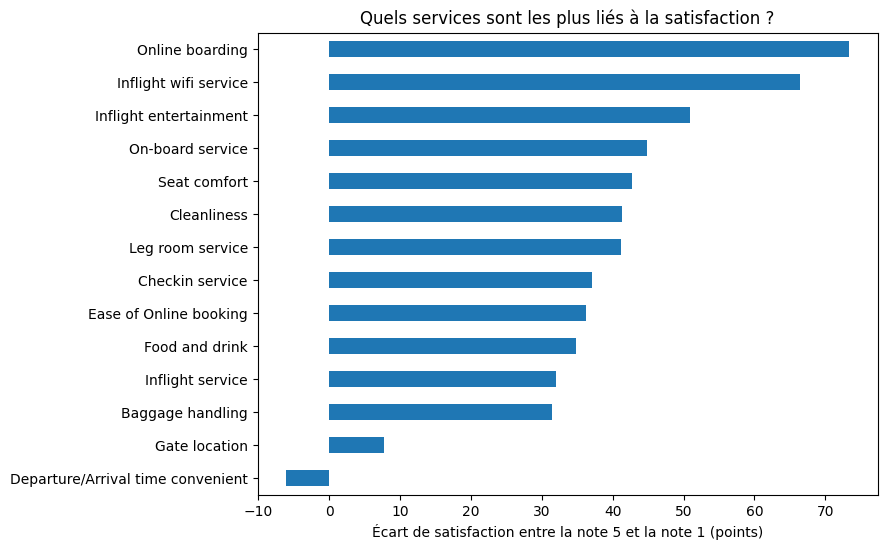

In [3]:
tableau["ecart"].sort_values().plot(kind="barh", figsize=(8, 6))
plt.xlabel("Écart de satisfaction entre la note 5 et la note 1 (points)")
plt.title("Quels services sont les plus liés à la satisfaction ?")
plt.savefig(RACINE / "figures" / "02_ecart_par_note.png", bbox_inches="tight")
plt.show()


In [4]:
def ecart(groupe):
    resultat = {}
    for note in RATING_COLS:
        taux = groupe.groupby(note)["satisfait"].mean() * 100
        resultat[note] = taux[5] - taux[1]
    return pd.Series(resultat).round(1)

affaires_business = df[(df["Type of Travel"] == "Business travel") & (df["Class"] == "Business")]
affaires_eco = df[(df["Type of Travel"] == "Business travel") & (df["Class"] == "Eco")]
perso_eco = df[(df["Type of Travel"] == "Personal Travel") & (df["Class"] == "Eco")]

profil = pd.DataFrame({
    "tous": ecart(df),
    "affaires en Business": ecart(affaires_business),
    "affaires en Eco": ecart(affaires_eco),
    "personnel en Eco": ecart(perso_eco),
}).sort_values("tous", ascending=False)

profil.to_csv(RACINE / "results" / "02_ecart_par_profil.csv")
profil


,tous,affaires en Business,affaires en Eco,personnel en Eco
Online boarding,73.4,62.1,83.5,31.7
Inflight wifi service,66.5,32.0,99.0,100.0
Inflight entertainment,50.9,69.1,43.0,-0.1
On-board service,44.9,64.1,38.7,-0.7
Seat comfort,42.7,47.4,31.8,0.2
Cleanliness,41.3,59.0,33.6,-0.0
Leg room service,41.2,60.3,11.9,5.8
Checkin service,37.1,54.2,34.2,0.5
Ease of Online booking,36.2,10.6,36.4,72.0
Food and drink,34.9,46.6,30.9,0.8


In [5]:
PROFIL = ["Customer Type", "Type of Travel", "Class", "Age", "Flight Distance", "Arrival Delay in Minutes"]
X = pd.get_dummies(df[RATING_COLS + PROFIL], drop_first=True).astype(float).fillna(0)
y = df["satisfait"]

X_app, X_val, y_app, y_val = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)

foret = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1).fit(X_app, y_app)
print("Bonnes réponses sur la validation :", round(foret.score(X_val, y_val), 3))

imp = permutation_importance(foret, X_val, y_val, n_repeats=5, random_state=SEED, n_jobs=-1)
importance = pd.Series(imp.importances_mean, index=X.columns).sort_values(ascending=False).round(4)

importance.to_csv(RACINE / "results" / "02_importance.csv")
importance


Bonnes réponses sur la validation : 0.963


Type of Travel_Personal Travel       0.1306
Inflight wifi service                0.1297
Customer Type_disloyal Customer      0.0528
Online boarding                      0.0335
Checkin service                      0.0279
Baggage handling                     0.0219
Seat comfort                         0.0179
Class_Eco                            0.0176
Cleanliness                          0.0168
Inflight service                     0.0155
Inflight entertainment               0.0057
On-board service                     0.0054
Leg room service                     0.0046
Age                                  0.0032
Ease of Online booking               0.0015
Gate location                        0.0014
Departure/Arrival time convenient    0.0012
Flight Distance                      0.0010
Arrival Delay in Minutes             0.0008
Class_Eco Plus                       0.0006
Food and drink                       0.0006
dtype: float64